# Problemas inversos discretos e lineares

Nesta aula queremos construir uma noção de dificuldade sobre os problemas inversos. Vamos montar alguns problemas simples e de pequenas dimensões e avaliar aspectos sobre a qualidade dos dados medidos (erros e ruído em $\mathbf{b}$) e do modelo de mundo que possuímos (algumas propriedades de $\mathbf{A}$ e $\mathbf{A}^{-1}$ - quando a última existe).

Vimos que os problemas inversos são alguns dos problemas matemáticos mais importantes nas ciências e na matemática, pois nos informam sobre parâmetros que não podemos observar diretamente. Um esquema da nossa tarefa é apresentado a seguir: 

- nós conhecemos as saídas (medidas com algum erro ou incerteza);
- também conhecemos (em geral) o modelo matemático (ou sistema);
- o que desejamos **inferir** são as entradas (a causa por trás do que medimos); 

<figure style="text-align: center;">
    <img src="\..\figs\probinv_conceito.png" width="500" alt="Imagem do conceito do problema inverso.">
    <figcaption style="margin-top: 8px; font-style: italic; color: #555;">
        Figure 3: Conceito do problema inverso (Fonte: Discrete Inverse Problems Insight and Algorithms, Per Christian Hansen, SIAM, Fig. 1.3).
    </figcaption>
</figure>

Vimos também que nossas medições serão sempre discretas (uma coleção de dados organizada em um **vetor**). Além disso, frequentemente, o modelo matemático pode ser **linear**. Isso implica podemos escrever um modelo pro nosso universo investigado numa versão matricial, dada por

\begin{equation}
\mathbf{b}= \mathbf{A} \mathbf{x} + \mathbf{n},
\tag{1}
\end{equation}

em que 

- $\mathbf{b} = \left[b_1, b_2, \cdots b_M\right]^T \in \mathbb{C}^{M \times 1}$ é o vetor de observações (ou medições); ele contém uma série de números (reais ou, de forma genérica, complexos);
- $\mathbf{A} \in \mathbb{C}^{M \times L}$ é a matriz de sensibilidade do problema; ela contém uma série de números (ou coeficientes), que são computados pela função $f(\mathbf{\Theta}, \mathbf{r},t)$ medidos discretamente nas variáveis independentes;
- $\mathbf{x} = \left[x_1, x_2, \cdots x_L\right]^T \in \mathbb{C}^{L \times 1}$ é o vetor de coeficientes de $\mathbf{\Theta}$ com a solução desejada do problema inverso.
- $\mathbf{n} \in \mathbb{C}^{M \times 1}$ é o ruído associado à medição (frequentemente desconhecido).

Vamos dar um passo atrás e assumir que $\mathbf{n} \approx \mathbf{0}$. Assim,

## 1. Matrizes e sistemas de equações

\begin{equation}
\mathbf{A} \mathbf{x} = \mathbf{b}
\tag{2}
\end{equation}

A Eq.(2) representa um *sistema de equações*. Então, de forma geral, se $\mathbf{A} \in \mathbb{C}^{M \times L}$, temos um sistema de equações com

- $M$ **equações**, e
- $L$ **incógnitas**.

Vamos tentar pensar em algo simples. Por ora, um sistema de equações com $M=L=2$. Por exexplo,

\begin{equation}
\begin{cases}
1x_1 + 2x_2 = 3 \\
4x_1 + 5x_2 = 6
\end{cases}
\end{equation}

Neste caso, podemos escrever matricialmente como

\begin{equation}
\underbrace{
\begin{bmatrix}
1 & 2 \\
4 & 5
\end{bmatrix}}_{\text{sensing matrix}}
\overbrace{\begin{bmatrix}
x_1 \\ x_2
\end{bmatrix}}^{\text{solution}}
 \ \ \ \ =
\underbrace{\begin{bmatrix}
3 \\ 6
\end{bmatrix}}_{\text{measurements}}
\end{equation}

Nós sabemos como resolver este tipo de sistema de equações. Usualmente...

- Fazemos algum tipo de manipulação (eliminação) e resolvemos com papel e caneta. É muito simples no caso $2 \times 2$;
- Nós também podemos usar a regra do determinante (papel e caneta ou no computador);
- ou ir direto à solução computacional calculando a matriz inversa, $\mathbf{A}^{-1}$, na forma

\begin{equation}
\mathbf{\tilde{x}}= \mathbf{A}^{-1} \mathbf{b},
\end{equation}
que chamamos de **solução ingênua** (veremos a razão deste nome).

Vamos começar com uma noção geométrica e compará-la à solução computacional. O caso $2 \times 2$ é útil porque nos permite:

- visualização fácil;
- vislumbrar como podemos falhar tão miseravelmente num problema tão simples.

Em 2D, podemos tratar as equações do sistema como 2 retas, da seguinte forma:

\begin{equation}
\begin{cases}
x_2 = \frac{1}{2}(3 - 1 x_1) \\
x_2 = \frac{1}{5}(6 - 4 x_1)
\end{cases}
\end{equation}

Vamos plotar ambas as retas e ver onde elas se interceptam (esta é a nossa **solução**)

In [1]:
import numpy as np # arrays
import matplotlib.pyplot as plt # plots
import IPython.display as ipd # to play signals
np.set_printoptions(precision=5)
import cvxpy as cp

Sensing matrix:
 [[1 2]
 [4 5]]
Inversa:
 [[-1.66667  0.66667]
 [ 1.33333 -0.33333]]
Determinante da matriz A é -3.0000
Vetor solução é (-1.0000, 2.0000)


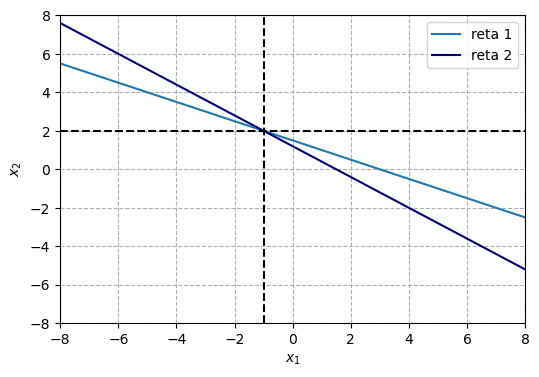

In [2]:
# Sensing matrix
A = np.array([[1,2], [4,5]])
# Sensing matrix inverse
Ainv = np.linalg.inv(A)
print("Sensing matrix:\n {}".format(A))
print("Inversa:\n {}".format(Ainv))

# Column vectors 
v_1 = A[:,0]
v_2 = A[:,1]

# Measurement
b = np.array([3,6])

# Two lines
x_1_vi = np.linspace(-8, 8, 100)
x_21 = (1/A[0,1])*(b[0]-A[0,0]*x_1_vi)
x_22 = (1/A[1,1])*(b[1]-A[1,0]*x_1_vi)

# Determinant rule
den = np.linalg.det(A)
print("Determinante da matriz A é {:.4f}".format(den))

num_x1 = np.linalg.det(np.column_stack((b, v_2)))
num_x2 = np.linalg.det(np.column_stack((v_1, b)))
x_1 = num_x1/den
x_2 = num_x2/den
print("Vetor solução é ({:.4f}, {:.4f})".format(x_1, x_2))

# Plot
plt.figure(figsize = (6,4))
plt.plot(x_1_vi, x_21, color = 'tab:blue', label = "reta 1")
plt.plot(x_1_vi, x_22, color = 'navy', label = "reta 2")
plt.axvline(x_1, color = 'k', linestyle = '--')
plt.axhline(x_2, color = 'k', linestyle = '--')

plt.legend()
plt.grid(linestyle = '--')
plt.xlim((x_1_vi[0], x_1_vi[-1]))
plt.ylim((x_1_vi[0], x_1_vi[-1]))
plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$");

## 2. O espaço dos vetores coluna

Um outro ponto de vista sobre a equação na forma matricial consiste em utilizar uma combinação linear dos vetores coluna, da seguinte forma

\begin{equation}
\begin{bmatrix}
1 \\ 4 
\end{bmatrix}
x_1 +
\begin{bmatrix}
2 \\ 5
\end{bmatrix}
x_2 =
\begin{bmatrix}
3 \\ 6
\end{bmatrix}
\end{equation}

e a questão agora é pensar em que valores escalares de $x_1$ e $x_2$ levam os vetores coluna $[1, 4]^T$ e $[2, 5]^T$ para o vetor solução $[3, 6]^T$?

Vamos plotar essa intuição

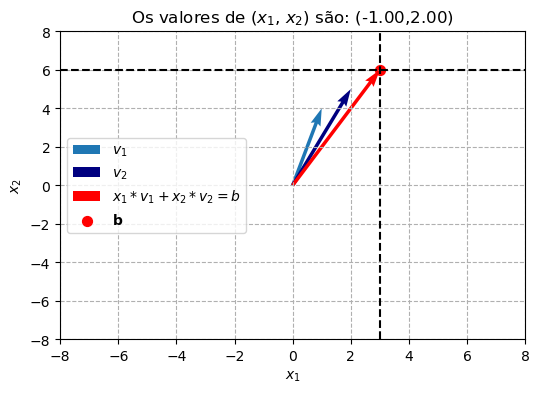

In [4]:
origin = np.array([0, 0])
v_sum = x_1 * v_1 +  x_2 * v_2

# Plot
plt.figure(figsize = (6,4))
plt.quiver(*origin, *v_1, angles='xy', scale_units='xy', scale=1, color='tab:blue', label = r"$v_1$")
plt.quiver(*origin, *v_2, angles='xy', scale_units='xy', scale=1, color='navy', label = r"$v_2$")
plt.quiver(*origin, *v_sum, angles='xy', scale_units='xy', scale=1, color='red', label = r"$x_1*v_1 + x_2*v_2 = b$")
plt.scatter(*b, c = 'r', s = 50, label = r'$\mathbf{b}$')

plt.axvline(3, color = 'k', linestyle = '--')
plt.axhline(6, color = 'k', linestyle = '--')
plt.legend()
plt.grid(linestyle = '--')
plt.xlim((x_1_vi[0], x_1_vi[-1]))
plt.ylim((x_1_vi[0], x_1_vi[-1]))
plt.title(r"Os valores de ($x_1$, $x_2$) são: ({:.2f},{:.2f})".format(x_1, x_2))
plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$");

## Pergunta:
$\mathbf{v}_1$ e $\mathbf{v}_2$ são colineares? Há um ângulo significativo entre eles? Eles são ortogonais?
<details>
  <summary><b>▶ Clique aqui para ver a resposta</b></summary>
  
  <br>
  
  ### Resposta
  Eles não são ortogonais, mas não são colineares. Há um ângulo significativo entre eles. Ou seja, combiná-los de alguma forma te leva ao vetor $\mathbf{b}$.
  
</details>

## 3. Quando as coisas começam a dar terrivelmente errado.

Poderíamos parar aqui se tudo fosse assim bem comportado. Infelizmente, esta não é a realidade. Então, o que pode dar errado?

#### A. Quando as retas são paralelas.

Imagine agora o seguinte sistema de equações (já em forma matricial)

\begin{equation}
\begin{bmatrix}
1 & 2 \\
4 & 8
\end{bmatrix}
\begin{bmatrix}
x_1 \\ x_2
\end{bmatrix}
=
\begin{bmatrix}
3 \\ 6
\end{bmatrix}
\end{equation}

Se multiplicarmos a primeira linha da matriz $\mathbf{A}$ por 4, chegamos a segunda linha. Ou você pode pensar em multiplicar as colunas por 2. Dá no mesmo. 

Note também que os vetores coluna $\mathbf{v}_1 = [1, 4]^T$ e $\mathbf{v}_2 = [2, 8]^T$ são colineares. Do produto interno, nota-se que o ângulo entre eles é nulo.

**Ou seja:** é impossível combinar os vetores das colunas e chegar a qualquer ponto fora da linha que passa pelos vetores no espaço 2D.

Neste caso dizemos que a matriz $\mathbf{A}$ é **singular** (e completamente inútil).

Vejamos o que ocorre com nossa noção geométrica.

cossine beteen v_1 and v_2 is 1.000
Determinante da matriz A é 0.0000
Vetor solução é (inf, -inf)


C:\Users\Win11\AppData\Local\Temp\ipykernel_20820\4236446893.py:24: RuntimeWarning: divide by zero encountered in scalar divide
  x_1 = num_x1/den
C:\Users\Win11\AppData\Local\Temp\ipykernel_20820\4236446893.py:25: RuntimeWarning: divide by zero encountered in scalar divide
  x_2 = num_x2/den


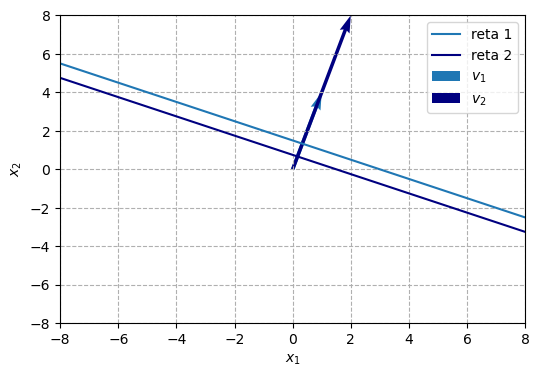

In [5]:
# Sensing matrix
A = np.array([[1,2], [4,8]])

# Column vectors 
v_1 = A[:,0]
v_2 = A[:,1]
cos_theta_v1_v2 = np.dot(v_1, v_2)/(np.linalg.norm(v_1)*np.linalg.norm(v_2))
print(r"cossine beteen v_1 and v_2 is {:.3f}".format(cos_theta_v1_v2))

# Measurement
b = np.array([3,6])

# Two lines
x_1_vi = np.linspace(-8, 8, 100)
x_21 = (1/A[0,1])*(b[0]-A[0,0]*x_1_vi)
x_22 = (1/A[1,1])*(b[1]-A[1,0]*x_1_vi)

# Determinant rule
den = np.linalg.det(A)
print("Determinante da matriz A é {:.4f}".format(den))

num_x1 = np.linalg.det(np.column_stack((b, v_2)))
num_x2 = np.linalg.det(np.column_stack((v_1, b)))
x_1 = num_x1/den
x_2 = num_x2/den
print("Vetor solução é ({:.4f}, {:.4f})".format(x_1, x_2))



# Plot
plt.figure(figsize = (6,4))
plt.plot(x_1_vi, x_21, color = 'tab:blue', label = "reta 1")
plt.plot(x_1_vi, x_22, color = 'navy', label = "reta 2")
plt.quiver(*origin, *v_1, angles='xy', scale_units='xy', scale=1, color='tab:blue', label = r"$v_1$")
plt.quiver(*origin, *v_2, angles='xy', scale_units='xy', scale=1, color='navy', label = r"$v_2$")

plt.legend()
plt.grid(linestyle = '--')
plt.xlim((x_1_vi[0], x_1_vi[-1]))
plt.ylim((x_1_vi[0], x_1_vi[-1]))
plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$");

#### B. Quando a matriz é quase singular.

Imagine agora o seguinte sistema de equações (já em forma matricial)

\begin{equation}
\begin{bmatrix}
1 & 2 \\
4 & 8+c
\end{bmatrix}
\begin{bmatrix}
x_1 \\ x_2
\end{bmatrix}
=
\begin{bmatrix}
3 \\ 6
\end{bmatrix}
+
\begin{bmatrix}
n_1 \\ n_2
\end{bmatrix}
\end{equation}

em que $c\approx 0$ (um número pequeno) $\mathbf{n} = [n_1, n_2]^T$ pode ser visto como uma pequena perturbação na solução, associada a **erros** de medição ou **ruído**.

cossine beteen v_1 and v_2 is 0.99999996
Noise vector: [ 0.0631  -0.09525]
Determinante da matriz A é 0.0100
Solução verdadeira é (-1.0000, 2.0000)
Vetor solução é (1272.5919, -634.7644)
Norma da solução é: 1422.12


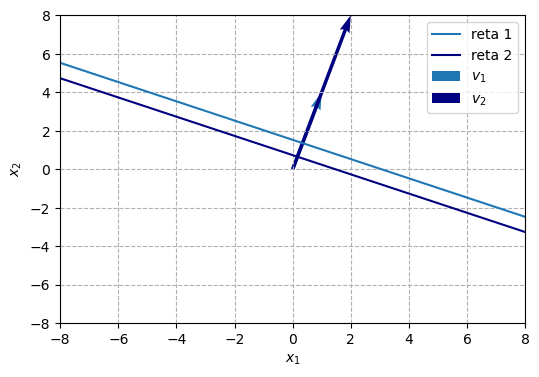

In [6]:
# Sensing matrix
c = 0.01
A = np.array([[1,2], [4,8+c]])

# Column vectors 
v_1 = A[:,0]
v_2 = A[:,1]
cos_theta_v1_v2 = np.dot(v_1, v_2)/(np.linalg.norm(v_1)*np.linalg.norm(v_2))
print(r"cossine beteen v_1 and v_2 is {:.8f}".format(cos_theta_v1_v2))

# Measurement
noise = np.random.normal(loc=0.0, scale=0.1, size=2)
print("Noise vector: {}".format(noise))
b = np.array([3,6]) + noise

# Two lines
x_1_vi = np.linspace(-8, 8, 100)
x_21 = (1/A[0,1])*(b[0]-A[0,0]*x_1_vi)
x_22 = (1/A[1,1])*(b[1]-A[1,0]*x_1_vi)

# Determinant rule
den = np.linalg.det(A)
print("Determinante da matriz A é {:.4f}".format(den))

num_x1 = np.linalg.det(np.column_stack((b, v_2)))
num_x2 = np.linalg.det(np.column_stack((v_1, b)))
x_1 = num_x1/den
x_2 = num_x2/den

print("Solução verdadeira é ({:.4f}, {:.4f})".format(-1.00, 2.000))
print("Vetor solução é ({:.4f}, {:.4f})".format(x_1, x_2))
print("Norma da solução é: {:.2f}".format(np.linalg.norm(np.array([x_1, x_2]))))

# Plot
plt.figure(figsize = (6,4))
plt.plot(x_1_vi, x_21, color = 'tab:blue', label = "reta 1")
plt.plot(x_1_vi, x_22, color = 'navy', label = "reta 2")
plt.quiver(*origin, *v_1, angles='xy', scale_units='xy', scale=1, color='tab:blue', label = r"$v_1$")
plt.quiver(*origin, *v_2, angles='xy', scale_units='xy', scale=1, color='navy', label = r"$v_2$")

plt.legend()
plt.grid(linestyle = '--')
plt.xlim((x_1_vi[0], x_1_vi[-1]))
plt.ylim((x_1_vi[0], x_1_vi[-1]))
plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$");

## O que você observa?
<details>
  <summary><b>▶ Clique aqui para ver a resposta</b></summary>
  
  <br>
  
  ### Resposta
  Num sistema de equações com uma matriz **quase singular** pequenas perturbações na medição, levam a soluções $\mathbf{x}$ completamente diferentes.

  Pense por um instante: se isso já é uma realidade num sistema $2 \times 2$, imagine o que ocorre num sistema com centenas de equações e incógnitas?
  
</details>

#### C. Quando a matriz não é quadrada.

Os problemas em que a matriz $\mathbf{A} \in \mathbb{C}^{M \times L}$ é retangular são comuns na prática. Duas possibilidades podem acontecer:

- $M>L$: você tem mais equações (**medições**) que incógnitas (muito recomendável, se possível);
- $M<L$: seu modelo de mundo tem mais incógnitas do que você tem equações (ou **medições** disponíveis);

Vamos entender os desafios do ponto de vista geométrico. Então, imagine o sistema de equações, com $M = 3$ e $L = 2$, dado abaixo. Note que o determinante de $\mathbf{A}$ não é mais computável, pois $\mathbf{A}$ é retangular. Note também que agora temos 3 retas (e não 2).


\begin{equation}
\begin{bmatrix}
1 & 2 \\
4 & 5 \\
7 & 3
\end{bmatrix}
\begin{bmatrix}
x_1 \\ x_2
\end{bmatrix}
=
\begin{bmatrix}
3 \\ 6 \\ 5
\end{bmatrix}
\end{equation}

com $M = 3$ e $L = 2$

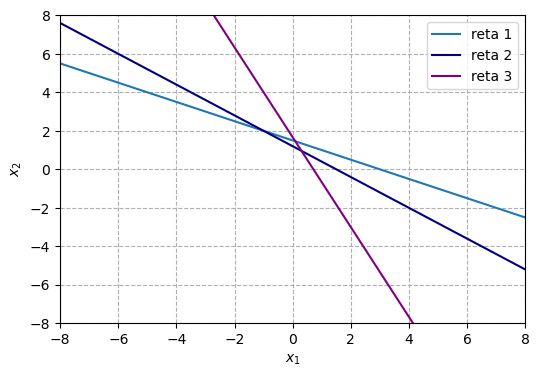

In [7]:
# Sensing matrix
A = np.array([[1,2], [4,5], [7,3]])
# Column vectors 
v_1 = A[:,0]
v_2 = A[:,1]

# Measurement
b = np.array([3,6, 5])

# Three lines
x_1_vi = np.linspace(-8, 8, 100)
x_21 = (1/A[0,1])*(b[0]-A[0,0]*x_1_vi)
x_22 = (1/A[1,1])*(b[1]-A[1,0]*x_1_vi)
x_23 = (1/A[2,1])*(b[2]-A[2,0]*x_1_vi)

# Determinant rule
# Plot
plt.figure(figsize = (6,4))
plt.plot(x_1_vi, x_21, color = 'tab:blue', label = "reta 1")
plt.plot(x_1_vi, x_22, color = 'navy', label = "reta 2")
plt.plot(x_1_vi, x_23, color = 'purple', label = "reta 3")

plt.legend()
plt.grid(linestyle = '--')
plt.xlim((x_1_vi[0], x_1_vi[-1]))
plt.ylim((x_1_vi[0], x_1_vi[-1]))
plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$");

## O que você observa?
<details>
  <summary><b>▶ Clique aqui para ver a resposta</b></summary>
  
  <br>
  
  ### Resposta
  Neste caso temos aparentemente 3 encontros entre pares de retas. Todos são soluções válidas para o sistema de equações e, em essência, não temos
como determinar qual a correta. O melhor que poderíamos fazer neste caso é concordar que talvez a melhor solução seja aquela com a menor norma.
  
</details>

## 4. Span, espaço de colunas e o espaço nulo de uma matriz

Os conceitos de *span*, espaço de colunas (*column space*) e espaço nulo (*null space*) dão boas noções sobre a qualidade da matriz $\textbf{A}$.


### A. Span

- O *span* de um conjunto de $k$ vetores $\mathbf{v_i} \in \mathbb{R}^{N}$ é o subespaço linear gerado por todas as combinações lineares desses vetores.

### B. Column space

No caso da matriz $\mathbf{A}$, você pode pensar nela como uma coleção de vetores coluna. Assim, seu *span* define quais são as possibilidades de medições $\mathbf{b}$ que conseguimos representar com o modelo  $\mathbf{A}$. Dizemos que um sistema linear de equações $\mathbf{Ax} = \mathbf{b}$ é compatível se o lado a direita da igualdade, $\mathbf{b}$, está no espaço de colunas de $\mathbf{A}$ [$\mathbf{b} \in \mathcal{C}(\mathbf{A})$].

O que fica claro é:

- No caso da matriz **não-singular** e $2 \times 2$, essencialmente podemos usar $\mathbf{A}$ pra chegar a qualquer possível medição $\mathbf{b}$.
- No caso da matriz **singular** ou **quase singular**, nossas opções são muito limitadas. O $\text{span}(\mathbf{A})$ vai ser menor que $M$ ou $L$.

### C. Null space

De forma similar, definimos o espaço nulo de $\mathbf{A}$ como o espaço coberto por todas as operações $\mathcal{N}(\mathbf{A}) = \left\{\mathbf{x} \in \mathbb{R}^{N} | \mathbf{Ax} = \mathbf{0}\right\}$.

 # A história até aqui.

 Achar soluções sensatas para o problema

\begin{equation}
\textbf{A} \textbf{x} = \textbf{b},
\end{equation}

quase nunca é uma tarefa trivial. A matriz inversa $\textbf{A}^{-1}$ só existe quando $M=L$ e $\textbf{A}$ não é singular nem quase singular. No último caso, pequenos erros de medição $\textbf{b}$ ou mesmo os erros de arredondamento podem levar a soluções $\textbf{x}$ muito distantes da realidade.  

Os problemas inversos do mundo real pertencem à classe de problemas que chamamos de *mal postos* (ou **ill-posed**). O termo foi cunhado no início do século XX por Hadamard (<a href="https://en.wikipedia.org/wiki/Jacques_Hadamard" target="_blank">Wikipedia Bio</a>), que trabalhou em problemas de física matemática. Ele acreditava que os problemas mal postos não modelam problemas do mundo real (**ele estava errado**). 

## 5. As condições de Hadamard

A definição de Hadamard diz que um problema linear é *bem colocado* (**well-posed**) se satisfizer os três requisitos seguintes:

1. **Existência:** O problema deve ter pelo menos uma solução. 
2. **Singularidade da solução (uniqueness):** Deve haver apenas **uma** solução para o problema. 
3. **Estabilidade:** A solução deve depender continuamente dos dados (pequenas perturbações não devem levar a grandes divergências na resposta).

Se o problema não satisfaz nenhuma dessas condições, ele é dito **ill-posed** (mal posto) — o que é muito frequente quando você quer estimar parâmetros de problemas interessantes e de escala média ou grande.

# Exercícios

Para cada um dos problemas abaixo, determine quais as condições de Hadamard são violadas.

(a)  
\begin{equation}
\begin{bmatrix}
1 & 2 \\
4 & 5
\end{bmatrix}
\begin{bmatrix}
x_1 \\ x_2
\end{bmatrix}
=
\begin{bmatrix}
3 \\ 6
\end{bmatrix}
\end{equation}

(b)  
\begin{equation}
\begin{bmatrix}
1 & 2 \\
4 & 8
\end{bmatrix}
\begin{bmatrix}
x_1 \\ x_2
\end{bmatrix}
=
\begin{bmatrix}
3 \\ 6
\end{bmatrix}
\end{equation}

(c)  
\begin{equation}
\begin{bmatrix}
1 & 2 \\
4 & 8
\end{bmatrix}
\begin{bmatrix}
x_1 \\ x_2
\end{bmatrix}
=
\begin{bmatrix}
3 \\ 12
\end{bmatrix}
\end{equation}

(d)  
\begin{equation}
\begin{bmatrix}
1 & 2.001 \\
4 & 8
\end{bmatrix}
\begin{bmatrix}
x_1 \\ x_2
\end{bmatrix}
=
\begin{bmatrix}
3 \\ 6
\end{bmatrix}
\end{equation}

(e)
\begin{equation}
\begin{bmatrix}
1 & 2 \\
4 & 5 \\
7 & 3
\end{bmatrix}
\begin{bmatrix}
x_1 \\ x_2
\end{bmatrix}
=
\begin{bmatrix}
3 \\ 6 \\ 5
\end{bmatrix}
\end{equation}

## 6. Medindo matrizes

Vamos discutir alguns exemplos a mais pra fortalecer nossa intuição. Vamos também adicionar algumas métricas importantes pra que consigamos mensurar a qualidade da solução de um problema inverso

\begin{equation}
\textbf{A} \textbf{x} = \textbf{b}.
\end{equation}

### A. Normas do resíduo e da solução

A primeira métrica é a norma do resíduo, dada por

\begin{equation}
r^2 = \left\|\textbf{Ax-b}\right\|_{2}^2,
\tag{3}
\end{equation}
que mensura o grau de ajuste do modelo, $\mathbf{A}\mathbf{x}$, relativo ao dado medido, $\mathbf{b}$.

<div style="background-color: #f0f2f5; padding: 15px; text-align: justify; border-radius: 8px; margin: 0 auto; max-width: 900px;">
$\mathbf{Dica}:$ um resíduo muito pequeno (num problema real) indica $\mathbf{overfitting}$. Seu modelo tem tantos parâmetros que se ajusta perfeitamente aos dados medidos, incluindo o ruído.
</div>

A segunda métrica é a norma da solução, dada por

\begin{equation}
s^2 = \left\|\textbf{x}\right\|_{2}^2,
\tag{4}
\end{equation}

<div style="background-color: #f0f2f5; padding: 15px; text-align: justify; border-radius: 8px; margin: 0 auto; max-width: 900px;">
$\mathbf{Dica}:$ soluções com norma muito elevada indicam instabilidades no problema numérico e, frequentemente, são não físicas (por ex., você tenta estimar as amplitudes de reflexão em um ultrassom e elas resultam em valores muito maiores do que os observados para a onda emitida pelo atuador).
</div>

### B. Norma da matriz, número de condição e rank

A norma Frobenius de uma matriz $\textbf{A} \in \mathbb{C}^{M \times L}$, dada por

\begin{equation}
\left\|\textbf{A}\right\|_{F}^{2} = \sum\limits_{i=1}^{M} \sum\limits_{j=1}^{L} |a_{ij}|^{2}
\tag{5}
\end{equation}

Uma outra forma de ver a questão é definir o quanto uma matriz consegue esticar um vetor:

\begin{equation}
\kappa= \text{max}\left(\left\|\textbf{Ax}\right\|_{2}\right/\left\|\textbf{x}\right\|_{2}) = \left\|\textbf{A}\right\|_{F}
\end{equation}

ou o quanto a matriz consegue encolher um vetor

\begin{equation}
\kappa'= \text{min}\left(\left\|\textbf{Ax}\right\|_{2}\right/\left\|\textbf{x}\right\|_{2}) = \text{min}\left(\left\|\textbf{b}\right\|_{2}\right/\left\|\textbf{A}^{-1}\textbf{b}\right\|_{2}) = \frac{1}{\left\|\textbf{A}^{-1}\right\|_{F}}
\end{equation}

O número de condição (**condition number**) tem como objetivo medir o quanto uma alteração no lado direito de um sistema de equações, as medições $\textbf{b}$, pode afetar a solução, $\textbf{x}$. 

Ele é definido por

\begin{equation}
\text{cond}(\textbf{A})= \frac{\kappa}{\kappa'}=  \left\|\textbf{A}\right\|_{F} \left\|\textbf{A}\right\|^{-1}_{F}
\tag{6}
\end{equation}

<div style="background-color: #f0f2f5; padding: 15px; text-align: justify; border-radius: 8px; margin: 0 auto; max-width: 900px;">
$\mathbf{Dica}:$ quanto maior for o  $\mathbf{condition \ number}$, mais sensível a solução é às perturbações em $\textbf{b}$ (incerteza ou ruído) e menos bem condicionado é o problema.
</div>


**OBS:** Por ora, essa definição implica que precisamos calcular as normas da matriz $\textbf{A}$ e de sua inversa, $\textbf{A}^{-1}$. Veremos adiante que isto não será necessário.

O **rank** de uma matriz pode ser definido como o número mínimo de linhas ou colunas linearmente independentes.

### Novos exemplos

Vamos agora avaliar:
- Matriz inversa (quando existir)
- norma do resíduo
- norma da solução
- número de condição

#### A. Um problema *well-posed*

Seja o problema:

\begin{equation}
\begin{bmatrix} 1.00 &3.00 \\ 2.70 & 1.80 \end{bmatrix} \ \textbf{x} = 
\begin{bmatrix} 1.00 \\ 2.20  \end{bmatrix}
\end{equation}

Como este é um problema bem condicionado e sem ruído, podemos considerar a solução ingênua como a verdadeira.

In [8]:
# Measurement
b = np.array([1, 2.2])
# Model
A = np.array([[1.00, 3.00],[2.70, 1.80]])
# Inverse matrix
Ainv = np.linalg.inv(A)
# Condition number
cnum = np.linalg.cond(A)
# Rank
rank = np.linalg.matrix_rank(A)
# Solution
x = Ainv @ b
print("Medição: {}".format(b))
print("Modelo:\n {}".format(A))
print("Inversa:\n {}".format(Ainv))
print("Condition number: {}".format(cnum))
print("Rank: {}".format(rank))
print("Sol: {}".format(x))
print("Norma da sol: {:.6f}".format(np.linalg.norm(x)))
print("Norma do resíduo: {:.16f}".format(np.linalg.norm(A@x-b)))

Medição: [1.  2.2]
Modelo:
 [[1.  3. ]
 [2.7 1.8]]
Inversa:
 [[-0.28571  0.47619]
 [ 0.42857 -0.15873]]
Condition number: 2.915767256700913
Rank: 2
Sol: [0.7619  0.07937]
Norma da sol: 0.766027
Norma do resíduo: 0.0000000000000004


#### B. $\textbf{A}$ é quase-singular

\begin{gather}
\begin{bmatrix} 1.00 & 3.00 \\ 1.01 & 2.98 \end{bmatrix} \ \textbf{x} = 
\begin{bmatrix} 1 \\ 2.2  \end{bmatrix}
\end{gather}

É muito difícil encontrar uma solução estável para o sistema de equações. Note que a matriz inversa apresenta entradas bastante grandes e que a solução ingênua ($\mathbf{A}^{-1}\mathbf{b}$) apresenta norma elevada. Note também o quanto o número de condição aumenta em relação ao exemplo anterior.

In [9]:
# Measurement
b = np.array([1, 2.2])
# Model
A = np.array([[1.00, 3.00],[1.01, 2.98]])# Inverse matrix
# Inverse matrix
Ainv = np.linalg.inv(A)
# Condition number
cnum = np.linalg.cond(A)
# Rank
rank = np.linalg.matrix_rank(A)
# Solution
x = Ainv @ b

print("Modelo:\n {}".format(A))
print("Inversa:\n {}".format(Ainv))
print("Condition number: {}".format(cnum))
print("Rank: {}".format(rank))
print("Sol: {}".format(x))
print("Norma da sol: {}".format(np.linalg.norm(x)))
print("Norma do resíduo: {:.16f}".format(np.linalg.norm(A@x-b)))

Modelo:
 [[1.   3.  ]
 [1.01 2.98]]
Inversa:
 [[-59.6  60. ]
 [ 20.2 -20. ]]
Condition number: 398.0074874844502
Rank: 2
Sol: [ 72.4 -23.8]
Norma da sol: 76.21154768143731
Norma do resíduo: 0.0000000000000027


#### C. E se adicionarmos ruído à medição?

No caso anterior, medimos $\textbf{b}$ com precisão. Mas isto não é realista. No mundo real, as medições têm ruído e incerteza. Vamos investigar o caso em que

\begin{equation}
\textbf{b}_n = \textbf{b} + \textbf{n}
\end{equation}

em que $\textbf{n}$ tem, geralmente, natureza aleatória. Cada vez que medimos, $\textbf{n}$ é diferente. Podemos investigar dois casos. 

##### No primeiro, a matriz $\textbf{A}$, que representa nosso modelo de mundo, é bem condicionada

\begin{equation}
\begin{bmatrix} 1.00 &3.00 \\ 2.70 & 1.80 \end{bmatrix} \ \textbf{x} = 
\textbf{b + n}
\end{equation}

##### No segundo, a matriz $\textbf{A}$ é mal condicionada

\begin{gather}
\begin{bmatrix} 1.00 & 3.00 \\ 1.01 & 2.98 \end{bmatrix} \ \textbf{x} = 
\textbf{b + n}
\end{gather}

In [10]:
# Model - Caso 1
A1 = np.array([[1.00, 3.00],[2.70, 1.80]])
A1inv = np.linalg.inv(A1)
# Condition number
cnum1 = np.linalg.cond(A1)
print("Condition number: {}".format(cnum1))

Condition number: 2.915767256700913


Noise: [-0.11671  0.21922]
True Solution: [0.7619  0.07937]
Norma da sol (true): 0.7660272071119782
Norma da sol (comp): 0.899658285315219
Solution of noisy: [ 0.89964 -0.00545]
Norma do resíduo: 2.2081065166053753
Erro absoluto: [0.13774 0.08482]


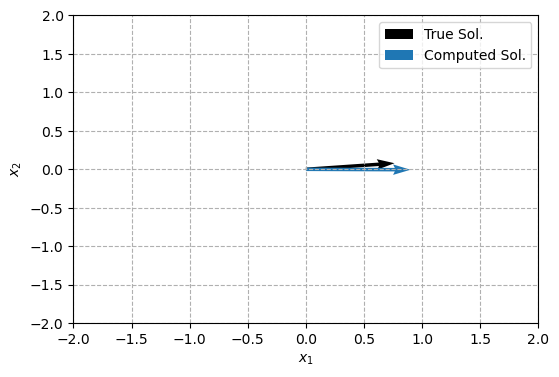

In [17]:
# Measurement
b = np.array([1, 2.2])
# True sol
x_true = np.linalg.inv(A1) @ b

# Noise
n = np.random.normal(loc = 0.0, scale = 0.5, size = len(b))
# Noisy measurement
bn = b + n
# solution
xn = A1inv @ bn

print("Noise: {}".format(n))
print("True Solution: {}".format(x_true))
print("Norma da sol (true): {}".format(np.linalg.norm(x_true)))
print("Norma da sol (comp): {}".format(np.linalg.norm(xn)))
print("Solution of noisy: {}".format(xn))
print("Norma do resíduo: {:.16f}".format(np.linalg.norm(A1inv@xn-b)))
print("Erro absoluto: {}".format(np.abs(x_true-xn)))

# Plot
origin = np.array([0, 0])
plt.figure(figsize = (6,4))
plt.quiver(*origin, *x_true, angles='xy', scale_units='xy', scale=1, color='k', label = "True Sol.")
plt.quiver(*origin, *xn, angles='xy', scale_units='xy', scale=1, color='tab:blue', label = "Computed Sol.")
plt.legend()
plt.grid(linestyle = '--')
plt.xlim((-2,2))
plt.ylim((-2,2))
plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$");

In [18]:
# Model - Caso 2
A2 = np.array([[1.00, 3.00],[1.01, 2.98]])
# Inverse matrix
A2inv = np.linalg.inv(A2)
# Condition number
cnum2 = np.linalg.cond(A2)
print("Condition number: {}".format(cnum2))

Condition number: 398.0074874844502


Noise: [0.25838 0.54372]
True Solution: [0.7619  0.07937]
Norma da sol (true): 0.7660272071119782
Norma da sol (comp): 94.33978736897774
Solution of noisy: [ 89.62362 -29.45508]
Norma do resíduo: 7503.1548141521807338
Erro absoluto: [88.86172 29.53445]


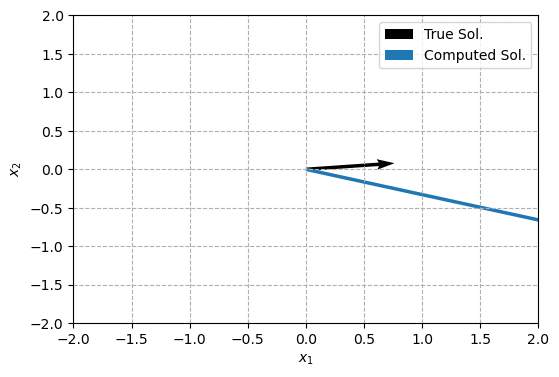

In [20]:
# Measurement
b = np.array([1, 2.2])
# True sol
x_true = np.linalg.inv(A1) @ b

# Noise
n = np.random.normal(loc = 0.0, scale = 0.5, size = len(b))
# Noisy measurement
bn = b + n
# solution
xn = A2inv @ bn

print("Noise: {}".format(n))
print("True Solution: {}".format(x_true))
print("Norma da sol (true): {}".format(np.linalg.norm(x_true)))
print("Norma da sol (comp): {}".format(np.linalg.norm(xn)))
print("Solution of noisy: {}".format(xn))
print("Norma do resíduo: {:.16f}".format(np.linalg.norm(A2inv@xn-b)))
print("Erro absoluto: {}".format(np.abs(x_true-xn)))

# Plot
origin = np.array([0, 0])
plt.figure(figsize = (6,4))
plt.quiver(*origin, *x_true, angles='xy', scale_units='xy', scale=1, color='k', label = "True Sol.")
plt.quiver(*origin, *xn, angles='xy', scale_units='xy', scale=1, color='tab:blue', label = "Computed Sol.")
plt.legend()
plt.grid(linestyle = '--')
plt.xlim((-2,2))
plt.ylim((-2,2))
plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$");

#### D. Existência e singularidade

É fácil formular problemas que possuem mais que uma solução possível.

\begin{gather}
\begin{bmatrix} 1 \\ 2 \end{bmatrix} \ x
 =
  \begin{bmatrix}
   1 \\
   2.2 
   \end{bmatrix}
\end{gather}

## Pergunta?
<details>
  <summary><b>▶ Quantas equações e incógnitas tem este problema?</b></summary>
  
  <br>
  
  ### Resposta
  2 equações e 1 incógnita. 

- $x = 1$ ?
- $2x = 2.2, \ \ \ x = 1.1$ ?
  
</details>

## 7. Pseudo inversa e a solução por mínimos quadrados 

**O que podemos fazer?**

Temos que reformular o problema. Uma possibilidade é usar uma solução por mínimos quadrados, que consiste em encontrar o vetor $\mathbf{x}$ que minimiza a norma do resíduo (diferença entre o que o modelo prediz, $\textbf{Ax}$, e o que medimos, $\textbf{b}$). Matematicamente

\begin{equation}
\tilde{x} = \text{min}(\left\|\textbf{Ax-b}\right\|^{2}_{2})
\end{equation}

Tal solução é equivalente ao seguinte (para o caso $2 \times 2$):

\begin{equation}
\frac{d(\left\|\textbf{Ax-b}\right\|^{2}_{2})}{dx} = 0
\end{equation}

\begin{equation}
\tilde{x}=\frac{a_{11} b_1 + a_{21} b_2}{a_{11}^{2}+a_{21}^{2}}
\end{equation}

Mas isso não é muito interessante, já que o problema tem uma dimensionalidade bem pequena. Podemos ser mais generalistas.

Seja $\textbf{A} \in \mathbb{C}^{M \times L}$, e $\textbf{b} \in \mathbb{C}^{M \times 1}$, de forma que $\textbf{x} \in \mathbb{C}^{L \times 1}$. Multiplicamos os dois lados da equação $\textbf{A x} = \textbf{b}$ por $\textbf{A}^{H}$ (pela esquerda). Assim:

\begin{equation}
\textbf{A}^H\textbf{A x} = \textbf{A}^H\textbf{b}
\end{equation}

O que significa que podemos achar uma aproximação para $\textbf{x}$ como

\begin{equation}
\tilde{x} = (\textbf{A}^H\textbf{A})^{-1}\textbf{A}^H\textbf{b}
\end{equation}

desde que $(\textbf{A}^H\textbf{A})^{-1}$ exista. A matriz

\begin{equation}
\textbf{A}^\dagger = (\textbf{A}^H\textbf{A})^{-1}\textbf{A}^H,
\end{equation}
é chamada de **Pseudo-Inversa** ou **Inversa de Moore-Penrose**. 

**IMPORTANTE:** Note que a solução por mínimos quadrados tende ao *overfitting*, já que minimiza a norma do resíduo.

In [21]:
# Measurement
b = np.array([1.0, 2.2])

# noise
n = np.random.normal(loc = 0.0, scale = 0.1, size = len(b))
b = b + n

# Model
A = np.array([[1],[2]])

# Solution 1
x1 = (np.linalg.inv(A.T @ A)) @ A.T @ b

# Solution 2

x2 = (A[0,0]*b[0] + A[1,0]*b[1]) / (A[0,0]**2 + A[1,0]**2)


# Solution 2
x3, residuals, rank , sigmas = np.linalg.lstsq(A, b, rcond = None)

print("Medição (com ruído): {}".format(b))
print("Modelo:\n {}".format(A))
print("Sol 1: {0:.5f}".format(x1[0]))
print("Sol 2: {0:.5f}".format(x2))
print("Sol 3: {0:.5f}".format(x3[0]))
print("Rank of A: {}".format(rank))

Medição (com ruído): [1.12873 2.10444]
Modelo:
 [[1]
 [2]]
Sol 1: 1.06752
Sol 2: 1.06752
Sol 3: 1.06752
Rank of A: 1


## 8. Over-determined vs. Under-determined

Nos problemas vistos anteriormente tínhamos mais equações que incógnitas. 

Neste caso, se $\textbf{A} \in \mathbb{C}^{M \times L}$, com $M > L$, temos, em geral, um sistema superdeterminado (**over-determined**), com mais equações que incógnitas. 

Apenas atente se as linhas (ou colunas) de $\textbf{A}$ são linearmente independentes.

In [22]:
A = np.array([[1.0, 3.0],[2.7, 1.8]])
rank1 = np.linalg.matrix_rank(A)

A[:,1] = 5.3*A[:,0] # coluna linearmente relacionada
rank2 = np.linalg.matrix_rank(A)

print("Shape de A: {}".format(A.shape))
print("Rank 1: {}".format(rank1))
print("Rank 2: {}".format(rank2))

Shape de A: (2, 2)
Rank 1: 2
Rank 2: 1


Sistemas subdeterminados **(under-determined)** são aqueles em que há menos equações do que incógnitas, $M<L$. 

Note, por exemplo, que quando fizemos a linha 2 (ou a coluna 2) de $\textbf{A}$ ser linearmente dependente da linha 1 (ou da coluna 1), o $\text{rank}(A) = 1$. Em essência, em vez de 2 equações e 2 incógnitas, temos agora 1 equação e 2 incógnitas. Nestes casos há infinitas soluções para o sistema de equações.

### A. Singularidade da solução

Nós podemos impor alguma outra condição para a solução. Por exemplo, considere o problema

\begin{equation}
x_1 + x_2 = 1 
\end{equation}

ou de forma matricial

\begin{equation}
\begin{bmatrix} 1.0 &  1.0 \end{bmatrix} \ \begin{bmatrix} x_1 \\ x_2 \end{bmatrix}
 = 1.0,
\end{equation}
em que $\mathbf{A} \in \mathbb{R}^{1 \times 2}$ (1 equação e 2 incógnitas) e há infinitas soluções possíveis, por exemplo:

- $\mathbf{x} = [0, 1]^T$
- $\mathbf{x} = [1, 0]^T$
- $\mathbf{x} = [2, -1]^T$
- $\mathbf{x} = [1000000, 0]^T$
- $\mathbf{x} = [1000000, -999999]^T$

Como reformular o problema de maneira sensata? Vamos considerar o seguinte: minimizar a norma da solução, sujeito ao requisito de que o resíduo seja nulo.

Se você pensou em *overfitting*, pensou corretamente, mas vamos em frente, de qualquer forma.

\begin{equation}
\text{min}(\left\|\textbf{x}\right\|^{2}_{2}), \ \ \, \text{subjected to} \ \ \ \textbf{Ax -  b} = 0
\end{equation}

Conseguimos montar o problema linear usando o multiplicador de Lagrange, que funciona da seguinte forma:

\begin{equation}
\text{min}(f(\textbf{x})), \ \ \, \text{subjected to} \ \ \ g(\textbf{x}) = 0
\end{equation}

A função de Lagrange é

\begin{equation}
\mathcal{L}(\textbf{x}, \lambda) = f(\textbf{x}) + \lambda g(\textbf{x})
\end{equation}

Precisamos encontrar:

\begin{equation}
\frac{\partial \mathcal{L}(\textbf{x}, \lambda)}{\partial x_1} = 0, \ \ \ \frac{\partial \mathcal{L}(\textbf{x}, \lambda)}{\partial x_2} = 0, \ \ \ \frac{\partial \mathcal{L}(\textbf{x}, \lambda)}{\partial \lambda} = 0 
\end{equation}


\begin{equation}
    \begin{cases}
      \frac{\partial \mathcal{L}(\textbf{x}, \lambda)}{\partial \lambda} = g(\textbf{x}) = 0  \\
      \frac{\partial f(\textbf{x})}{\partial x_1} + \lambda \frac{\partial g(\textbf{x})}{\partial x_1} = 0  \\
      \frac{\partial f(\textbf{x})}{\partial x_2} + \lambda \frac{\partial g(\textbf{x})}{\partial x_2} = 0
    \end{cases}\
\end{equation}

No nosso exemplo $f(\textbf{x}) = \left\|\textbf{x}\right\|^{2}_{2} = \sqrt{x_{1}^{2}+x_{2}^{2}}$, com $\frac{\partial f(\textbf{x})}{\partial x_1} = \frac{x_1}{\sqrt{x_{1}^{2}+x_{2}^{2}}}$ e $\frac{\partial f(\textbf{x})}{\partial x_2} = \frac{x_2}{\sqrt{x_{1}^{2}+x_{2}^{2}}}$.

Já  $g(\textbf{x}) = \textbf{Ax -  b} = x_1 + x_2 - 1$, com $\frac{\partial g(\textbf{x})}{\partial x_1} =\frac{\partial g(\textbf{x})}{\partial x_2} = 1$.

Assim, de um sistema com 1 equação e duas incógnitas, fomos para um sistema com 3 incógnitas $(x_1, x_2, \lambda)$ e 3 equações, a saber:

\begin{equation}
    \begin{cases}
      x_1 + x_2 -1 = 0  \ \ \ \ \ \ \ \ \ \ \ \ \ (1)\\
      \frac{x_1}{\sqrt{x_{1}^{2}+x_{2}^{2}}} + 1.0 \ \lambda = 0 \ \ \ \ \ \ (2) \\
      \frac{x_2}{\sqrt{x_{1}^{2}+x_{2}^{2}}} + 1.0 \ \lambda = 0 \ \ \ \ \ \ (3)
    \end{cases}\
\end{equation}

Fazendo (2) - (3): $x_1 = x_2$ (4). Colocando (4) em (1) vemos que $2 x_1 - 1 = 0$, $x_1 = x_2 = 1/2$.

Com um problema tão pequeno, é fácil resolvê-lo com papel e caneta. Mas vamos usar o **cvxpy** para montar e resolver o problema computacionalmente.

In [23]:
# Model
A = np.array([1.0, 1.0])

# Measurement
b = 1.0

# Create variable to be solved for.
x = cp.Variable(shape = 2)

# Create constraint.
constraints = [A@x - b == 0]

# Form objective.
obj = cp.Minimize(cp.norm(x, 2))

# Form and solve the problem.
prob = cp.Problem(obj, constraints)
prob.solve();

print("Sol: {}".format(x.value))

Sol: [0.5 0.5]


## 9. Estabilidade da solução e Regularização

A condição de estabilidade é muito mais difícil de "lidar" porque uma violação implica que perturbações arbitrariamente pequenas **nos dados medidos** podem produzir **perturbações arbitrariamente grandes na solução**. 

Pelo menos, isto é verdade para problemas de dimensão infinita; para problemas de dimensão finita, a perturbação é sempre finita, mas isto é irrelevante se a perturbação da solução for, digamos, da ordem de $10^{12}$.

Mais uma vez, a chave é reformular o problema de modo que a nova solução seja menos sensível às perturbações (ou ao *overfitting*). Dizemos que estabilizamos ou **regularizamos** o problema, de modo a que a solução se torne mais estável e regular. 

Talvez impor uma restrição do tipo $\left\|\textbf{Ax -  b}\right\|^{2}_{2} = 0$ não seja realista. Podemos pensar no seguinte: toda medição vai ter uma contaminação por ruído, de forma que:

\begin{equation}
\textbf{A x} = \textbf{b} + \textbf{n}, 
\end{equation}
assim, podemos pensar que a norma $\ell_2$ do resíduo, $\left\|\textbf{Ax -  b}\right\|^{2}_{2} \leq \left\|\textbf{n}\right\|^{2}_{2}$, estará limitada ao ruído, e escrever:

\begin{equation}
\text{min}(\left\|\textbf{x}\right\|^{2}_{2}), \ \ \, \text{subjected to} \ \ \ \left\|\textbf{Ax -  b}\right\|^{2}_{2} \leq \left\|\textbf{n}\right\|^{2}_{2}
\end{equation}

de forma que o resíduo entre modelo e medição seja menor que o ruído presente na medição. Note que toda vez que medirmos, a solução será estável.

In [24]:
# Model
A = np.array([1.0, 1.0])

# Measurement
b = 1.0
n = np.random.normal(loc = 0.0, scale = 0.05, size = 1)
bn = b + n

# Create variable to be solved for.
x = cp.Variable(shape = 2)

# Create constraint.
constraints = [cp.norm(A@x - b, 2) <= cp.norm(n,2)]

# Form objective.
obj = cp.Minimize(cp.norm(x, 2))

# Form and solve problem.
prob = cp.Problem(obj, constraints)
prob.solve();

print("SNR: {}".format(-10*np.log10(np.abs(n)**2/np.abs(b)**2)))
print("Sol: {}".format(x.value))

SNR: [26.08845]
Sol: [0.47519 0.47519]


### Vamos considerar mais um exemplo com "3 equações" e 2 incógnitas:

\begin{gather}
\begin{bmatrix} 0.16 & 0.10 \\ 0.17 & 0.11 \\ 2.02 & 1.29 \end{bmatrix} \ \textbf{x} = 
\begin{bmatrix} 0.26 \\ 0.28 \\ 3.31 \end{bmatrix} + \textbf{n}
\end{gather}

Neste caso 

\begin{gather}
\textbf{x}_{\text{exact}} =  
\begin{bmatrix} 1.00 \\ 1.00 \end{bmatrix}
\end{gather}

In [25]:
A = np.array([[0.16, 0.10],[0.17, 0.11],[2.02, 1.29]])
x_exact = np.array([1, 1]).T 
b_exact = A @ x_exact

print("Modelo:\n {}".format(A))
print("Medição exata (s/ ruído):\n {}".format(b_exact))
print("Sol exata: {}".format(x_exact))
print("Norma da sol.: {:.2f}".format(np.linalg.norm(x_exact)))

Modelo:
 [[0.16 0.1 ]
 [0.17 0.11]
 [2.02 1.29]]
Medição exata (s/ ruído):
 [0.26 0.28 3.31]
Sol exata: [1 1]
Norma da sol.: 1.41


### Agora, adicionamos ruído e notamos que a solução por mínimos quadrados não é estável.

Isto está ligado ao fato de que a matriz $\textbf{A}$ é mal-condicionada.

Medição (c/ ruído):
 [0.25073 0.27188 3.28791]
Sol. estimada: [0.2998  2.07851]
Norma da sol.: 2.10
Erro: [-0.7002   1.07851]
Rank of A: 2


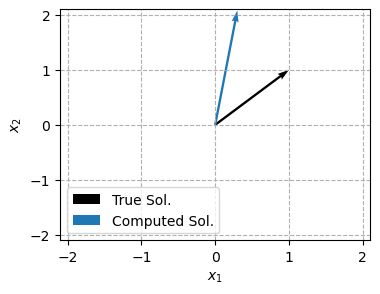

In [28]:
n = np.random.normal(loc = 0.0, scale = 0.01, size = len(b_exact))
bn = b_exact + n

# Solution 2
x_est, residuals, rank , sigmas = np.linalg.lstsq(A, bn, rcond = None)

print("Medição (c/ ruído):\n {}".format(bn))
print("Sol. estimada: {}".format(x_est))
print("Norma da sol.: {:.2f}".format(np.linalg.norm(x_est)))
print("Erro: {}".format(x_est-x_exact))
print("Rank of A: {}".format(rank))

# Plot
origin = np.array([0, 0])
plt.figure(figsize = (4,3))
plt.quiver(*origin, *x_exact, angles='xy', scale_units='xy', scale=1, color='k', label = "True Sol.")
plt.quiver(*origin, *x_est, angles='xy', scale_units='xy', scale=1, color='tab:blue', label = "Computed Sol.")
plt.legend(loc = 'lower left')
plt.grid(linestyle = '--')
plt.xlim((-np.linalg.norm(x_est),np.linalg.norm(x_est)))
plt.ylim((-np.linalg.norm(x_est),np.linalg.norm(x_est)))
plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$");

### Vamos reformular o problema para

\begin{equation}
\text{min}(\left\|\textbf{x}\right\|^{2}_{2}), \ \ \, \text{subjected to} \ \ \ \left\|\textbf{Ax -  b}\right\|^{2}_{2} \leq \left\|\textbf{n}\right\|^{2}_{2}
\end{equation}

Sol (True): [1 1]
Sol (Computed): [1.12176 0.71784]
Norma da sol.: 1.33
Erro: [ 0.12176 -0.28216]


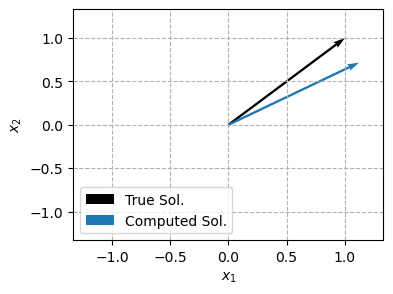

In [31]:
n = np.random.normal(loc = 0.0, scale = 0.1, size = len(b_exact))
bn = b_exact + n

# Create variable to be solved for.
x_est = cp.Variable(shape = 2)

# Create constraint.
constraints = [cp.norm(A @ x_est - bn, 2) <= cp.norm(n,2)]

# Form objective.
obj = cp.Minimize(cp.norm(x_est, 2))

# Form and solve problem.
prob = cp.Problem(obj, constraints)
prob.solve();

print("Sol (True): {}".format(x_exact))
print("Sol (Computed): {}".format(x_est.value))
print("Norma da sol.: {:.2f}".format(np.linalg.norm(x_est.value)))
print("Erro: {}".format(x_est.value-x_exact))


# Plot
origin = np.array([0, 0])
plt.figure(figsize = (4,3))
plt.quiver(*origin, *x_exact, angles='xy', scale_units='xy', scale=1, color='k', label = "True Sol.")
plt.quiver(*origin, *x_est.value, angles='xy', scale_units='xy', scale=1, color='tab:blue', label = "Computed Sol.")
plt.legend(loc = 'lower left')
plt.grid(linestyle = '--')
plt.xlim((-np.linalg.norm(x_est.value),np.linalg.norm(x_est.value)))
plt.ylim((-np.linalg.norm(x_est.value),np.linalg.norm(x_est.value)))
plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$");

# A história até aqui

Vimos que mesmo em problemas de pequena dimensionalidade, podemos ter situações de:

- múltiplas soluções possíveis
- instabilidade na solução.

Em geral, nossas medições ruidosas levarão a situações em que a solução é instável. A solução **ingênua** frequentemente é inútil. E se este é o caso pra um sistema pequeno ($2 \times 2$), imagine o que vai acontecer quando tivermos problemas de média e larga escala.  

Reformular um problema com múltiplas soluções (*overdetermined* ou *underdetermined*) é uma estratégia válida. No entanto, é preciso tomar cuidado com *overfitting* ao usar uma técnica como os mínimos quadrados. 

<div style="background-color: #f0f2f5; padding: 15px; text-align: justify; border-radius: 8px; margin: 0 auto; max-width: 900px;">
Uma solução $\mathbf{regularizada}$ consiste em reformular o problema de modo que a solução se ajuste bem aos dados medidos, sem sofrer $\mathbf{overfitting}$. Se bem feita, a solução tende a ser estável sob múltiplas condições de ruído.
</div>

A questão para a sequência é:

### Como podemos regularizar um problema inverso realmente interessante de forma adequada?

Vamos deixar isso para a sequência. Por hora, podemos apenas listar algumas propriedades e matrizes interessantes.

## 10. Matrizes especiais e algumas propriedades

Existem algumas estruturas matriciais nas quais temos um interesse especial, seja porque elas aparecerão com frequência, ou porque possuem propriedades interessantes.

#### A. Matriz diagonal

É uma matriz **quadrada** e $\in \mathbb{C}^{N \times N}$ do tipo

\begin{equation}
\mathbf{A} = 
\begin{bmatrix}
a_1 & 0 & \cdots & 0 \\
0 & a_2 & \cdots & 0 \\
\vdots & \vdots & \ddots & \vdots \\
0 & 0 & \cdots & a_N
\end{bmatrix}.
\end{equation}

Uma notação frequente é
\begin{equation}
\mathbf{A} = \text{diag}([a_1, a_2, \cdots, a_N]), 
\end{equation}

e sua inversa é
\begin{equation}
\mathbf{A}^{-1} = \text{diag}([1/a_1, 1/a_2, \cdots, 1/a_N]), 
\end{equation}

#### B. Matriz identidade

É um tipo especial de matriz diagonal. Uma matriz **quadrada** e $\in \mathbb{R}^{N \times N}$ do tipo

\begin{equation}
\mathbf{I} = 
\begin{bmatrix}
1 & 0 & \cdots & 0 \\
0 & 1 & \cdots & 0 \\
\vdots & \vdots & \ddots & \vdots \\
0 & 0 & \cdots & 1
\end{bmatrix}
\end{equation}

Naturalmente, para qualquer matriz quadrada $\mathbf{A}$ que possua uma inversa, ocorre que $\mathbf{A}^{-1}\mathbf{A} = \mathbf{I}$.

#### C. Matriz ortogonal

Uma matriz ortogonal é uma matriz cujas colunas são constituídas por vetores ortogonais, ou seja

\begin{equation}
\mathbf{Q} = 
\begin{bmatrix}
\mathbf{q}_1 & \mathbf{q}_2 & \cdots & \mathbf{q}_N
\end{bmatrix}
\end{equation}

com $\mathbf{q}_i \cdot \mathbf{q}_j = 0$, para $i \neq j$. Suas principais propriedades são

- $\mathbf{Q}^{-1} = \mathbf{Q}^{T}$ (fácil de inverter)
- $\mathbf{Q}^{T} \mathbf{Q} = \mathbf{Q} \mathbf{Q}^{T} = \mathbf{I}$
- $\text{det}(\mathbf{Q}) = \pm 1$

Caso a matriz seja complexa ($\in \mathbb{C}^{N \times N}$) a nomenclatura muda para "unitary matrix". Neste caso $\mathbf{Q}^{H} \mathbf{Q} = \mathbf{I}$.

#### D. Propriedades interessantes

- $\mathbf{I}^{-1} = \mathbf{I}$
- $\mathbf{A}^{-1}\mathbf{A} = \mathbf{I}$
- se $\mathbf{Q}$ é uma matriz ortogonal, $\mathbf{Q}^{-1} = \mathbf{Q}^{T}$ (fácil de inverter)

sejam $\mathbf{A}$ e $\mathbf{b}$ duas matrizes, e $\alpha$ um número real.

- $(\mathbf{A}^{H})^{H} = \mathbf{A}$
- $(\alpha \mathbf{A})^{H} = \alpha\mathbf{A}^{H}$
- $(\mathbf{A} + \mathbf{B})^{H} = \mathbf{A}^{H}+\mathbf{B}^{H}$
- $(\mathbf{A}\mathbf{B})^{H} = \mathbf{A}^{H}\mathbf{B}^{H}$

Seja o sistema de equações $\mathbf{Ax} = \mathbf{b}$. 

- Um sistema equivalente é $\mathbf{MAx} = \mathbf{Mb}$

podemos ver $\mathbf{M}$ como uma matriz que escalona as linhas ou colunas de $\mathbf{A}$. Em algumas aplicações é comum que tenhamos

- **medições** oriundas de diferentes sensores e, portanto, em diferentes escalas, resultando em uma matriz  $\mathbf{A}$ cuja norma de algumas linhas pode ser bem menor que a de outras.
- **modelo** que resulta numa matriz  $\mathbf{A}$ cuja norma de algumas colunas pode ser bem menor do que a de outras.